In [1]:
import numpy as np

# Create two vectors
v1 = np.array([1, 2, 3])
v2 = np.array([4, 5, 6])

# 1. Vector addition
def vector_addition(a, b):
    return a + b

# 2. Vector subtraction
def vector_subtraction(a, b):
    return a - b

# 3. Dot product
def dot_product(a, b):
    return np.dot(a, b)

# 4. Cross product (for 3D vectors)
def cross_product(a, b):
    return np.cross(a, b)

# 5. Vector magnitude
def vector_magnitude(a):
    return np.linalg.norm(a)

# Test your functions
print("Addition:", vector_addition(v1, v2))
print("Subtraction:", vector_subtraction(v1, v2))
print("Dot product:", dot_product(v1, v2))
print("Cross product:", cross_product(v1, v2))
print("Magnitude v1:", vector_magnitude(v1))

Addition: [5 7 9]
Subtraction: [-3 -3 -3]
Dot product: 32
Cross product: [-3  6 -3]
Magnitude v1: 3.7416573867739413


In [2]:
import numpy as np

# Create two matrices
m1 = np.array([[1, 2], [3, 4]])
m2 = np.array([[5, 6], [7, 8]])

# 1. Matrix addition
def matrix_addition(a, b):
    return a + b

# 2. Matrix subtraction
def matrix_subtraction(a, b):
    return a - b

# 3. Matrix multiplication
def matrix_multiplication(a, b):
    return np.matmul(a, b)

# 4. Matrix transpose
def matrix_transpose(a):
    return np.transpose(a)

# 5. Matrix determinant (for square matrices)
def matrix_determinant(a):
    return np.linalg.det(a)

# Test your functions
print("Matrix addition:\n", matrix_addition(m1, m2))
print("Matrix subtraction:\n", matrix_subtraction(m1, m2))
print("Matrix multiplication:\n", matrix_multiplication(m1, m2))
print("Matrix transpose m1:\n", matrix_transpose(m1))
print("Matrix determinant m1:", matrix_determinant(m1))

Matrix addition:
 [[ 6  8]
 [10 12]]
Matrix subtraction:
 [[-4 -4]
 [-4 -4]]
Matrix multiplication:
 [[19 22]
 [43 50]]
Matrix transpose m1:
 [[1 3]
 [2 4]]
Matrix determinant m1: -2.0000000000000004


In [3]:
import numpy as np

# 1. Vector scaling
def scale_vector(v, scalar):
    return scalar * v

# 2. Angle between two vectors (in radians)
def angle_between_vectors(a, b):
    cos_theta = np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))
    return np.arccos(np.clip(cos_theta, -1.0, 1.0))

# 3. Vector projection of a onto b
def vector_projection(a, b):
    return (np.dot(a, b) / np.dot(b, b)) * b

# 4. Rotate a 2D vector by theta radians
def rotate_vector_2d(v, theta):
    rotation_matrix = np.array([[np.cos(theta), -np.sin(theta)],
                               [np.sin(theta), np.cos(theta)]])
    return np.dot(rotation_matrix, v)

# Test your functions
v = np.array([1, 0])
print("Scaled vector:", scale_vector(v, 2.5))
print("Angle between v1 and v2:", angle_between_vectors(v1, v2))
print("Projection of v1 onto v2:", vector_projection(v1, v2))
print("Rotated vector:", rotate_vector_2d(v, np.pi/2))  # 90 degrees

Scaled vector: [2.5 0. ]
Angle between v1 and v2: 0.2257261285527342
Projection of v1 onto v2: [1.66233766 2.07792208 2.49350649]
Rotated vector: [6.123234e-17 1.000000e+00]


In [4]:
import numpy as np

# 1. Compute eigenvalues and eigenvectors
def compute_eigen(matrix):
    eigenvalues, eigenvectors = np.linalg.eig(matrix)
    return eigenvalues, eigenvectors

# 2. Verify that Av = λv for the first eigenvalue/eigenvector pair
def verify_eigen(matrix, eigenvalues, eigenvectors):
    # Get first eigenvalue and corresponding eigenvector
    λ = eigenvalues[0]
    v = eigenvectors[:, 0]

    # Compute Av and λv
    Av = np.dot(matrix, v)
    λv = λ * v

    # Check if they are approximately equal
    if np.allclose(Av, λv):
        print("Verification successful: Av = λv")
        print(f"Av: {Av}")
        print(f"λv: {λv}")
    else:
        print("Verification failed")

# Test with a sample matrix
sample_matrix = np.array([[2, -1], [-1, 2]])
eigenvalues, eigenvectors = compute_eigen(sample_matrix)
print("Eigenvalues:", eigenvalues)
print("Eigenvectors:\n", eigenvectors)
verify_eigen(sample_matrix, eigenvalues, eigenvectors)

Eigenvalues: [3. 1.]
Eigenvectors:
 [[ 0.70710678  0.70710678]
 [-0.70710678  0.70710678]]
Verification successful: Av = λv
Av: [ 2.12132034 -2.12132034]
λv: [ 2.12132034 -2.12132034]


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 61.0 MB/s eta 0:00:00
  Attempting uninstall: scikit-learn
    Found existing installation: scikit-learn 1.6.1
    Uninstalling scikit-learn-1.6.1:
      Successfully uninstalled scikit-learn-1.6.1


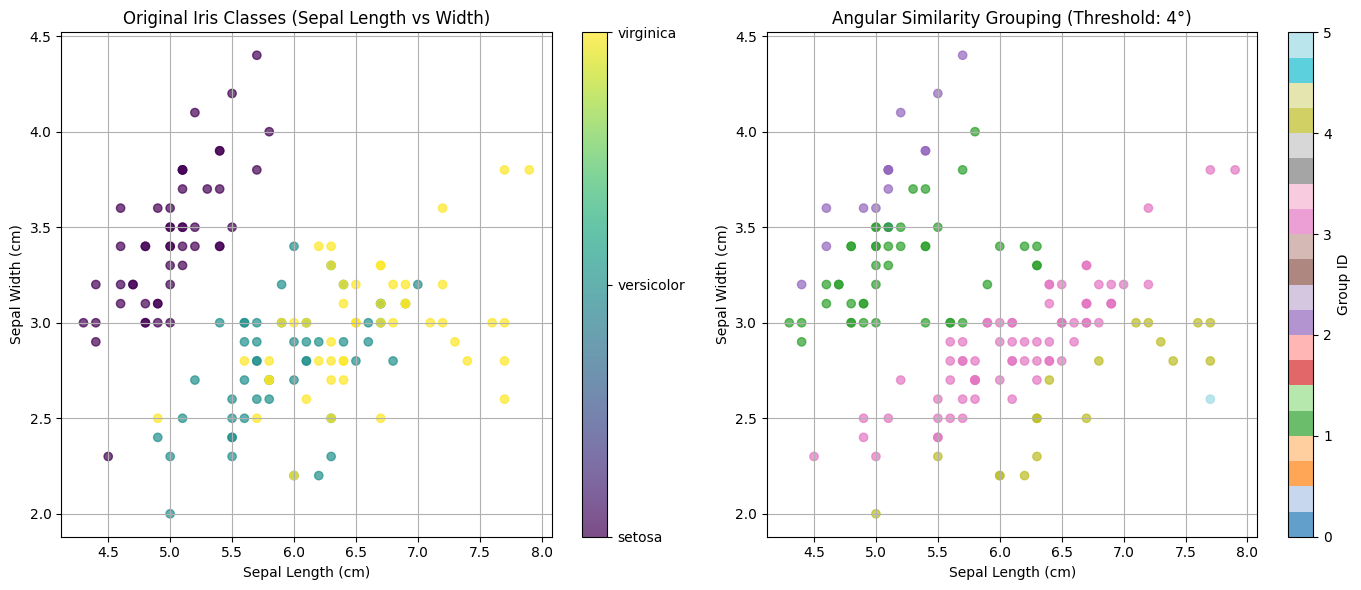

In [5]:
!pip install -U scikit-learn
from sklearn.datasets import load_iris
import numpy as np
import matplotlib.pyplot as plt

# Load the Iris dataset
iris = load_iris()
X = iris.data[:, :2]  # Using only sepal length and width
y = iris.target
target_names = iris.target_names  # Get the class names

def calculate_angle(a, b):
    """Calculate the angle between two vectors in degrees"""
    a_norm = a / np.linalg.norm(a)
    b_norm = b / np.linalg.norm(b)
    dot_product = np.clip(np.dot(a_norm, b_norm), -1.0, 1.0)
    return np.degrees(np.arccos(dot_product))

def group_by_angle(data, angle_threshold=30):
    """Group data points based on angular similarity"""
    n_samples = data.shape[0]
    groups = np.zeros(n_samples, dtype=int)
    current_group = 0

    for i in range(n_samples):
        if groups[i] == 0:
            groups[i] = current_group
            for j in range(i+1, n_samples):
                if groups[j] == 0:
                    angle = calculate_angle(data[i], data[j])
                    if angle < angle_threshold:
                        groups[j] = current_group
            current_group += 1
    return groups

# Run grouping
angle_threshold = 4
groups = group_by_angle(X, angle_threshold)

# Create figure with two subplots
plt.figure(figsize=(14, 6))

# Plot 1: Original Iris classes with names
plt.subplot(1, 2, 1)
scatter = plt.scatter(X[:, 0], X[:, 1], c=y, cmap='viridis', alpha=0.7)
plt.title("Original Iris Classes (Sepal Length vs Width)")
plt.xlabel("Sepal Length (cm)")
plt.ylabel("Sepal Width (cm)")
# Create colorbar with class names
cbar = plt.colorbar(scatter, ticks=[0, 1, 2])
cbar.ax.set_yticklabels(target_names)  # Set class names on colorbar
plt.grid(True)

# Plot 2: Angular similarity grouping
plt.subplot(1, 2, 2)
scatter = plt.scatter(X[:, 0], X[:, 1], c=groups, cmap='tab20', alpha=0.7)
plt.title(f"Angular Similarity Grouping (Threshold: {angle_threshold}°)")
plt.xlabel("Sepal Length (cm)")
plt.ylabel("Sepal Width (cm)")
plt.colorbar(scatter, label='Group ID')
plt.grid(True)

plt.tight_layout()
plt.show()